In [32]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [33]:
import numpy
import torch
import seaborn
from adaptive_nof1 import *
from adaptive_nof1.policies import *
from adaptive_nof1.helpers import *
from adaptive_nof1.inference import *
from adaptive_nof1.metrics import *
from adaptive_nof1.models import *
from matplotlib import pyplot as plt
from adaptive_nof1.patient_explorer import show_patient_explorer

In [34]:
# Initial parameters
block_length = 5
length = 6 * block_length
number_of_actions = 2
number_of_patients = 100

# Scenarios considered
## Linear Structural causal model with one-hot encoding
## Acne-dataset with weather as covariate
## "Back-pain" dataset with repeating covariate

In [35]:
# Scenarios
from adaptive_nof1.basic_types import Observation

class StructuralCausalModel(Model):
    def __init__(self, patient_id, starting_context, context_function, outcome_function, name, context_variance=1.0, outcome_variance=1.0):
        self.rng = numpy.random.default_rng(patient_id)
        self.starting_context = starting_context
        self.context_function = context_function
        self.outcome_function = outcome_function
        self.name = name
        self.patient_id = patient_id
        self.context_variance = context_variance
        self.outcome_variance = outcome_variance

    def generate_context(self, history):
        if len(history.observations) == 0:
            return {"L": self.context_function(**self.starting_context, k=0) + self.rng.normal(0, self.context_variance), **self.starting_context}
        
        last_observation = history.observations[-1]
        last_context = last_observation.context
        Y_k_minus_1 = last_observation.outcome["outcome"]
        L_k_minus_1 = last_context["L"]
        A_k_minus_1 = last_observation.treatment["treatment"]
        return {"L": self.context_function(Y_k_minus_1=Y_k_minus_1, L_k_minus_1=L_k_minus_1, A_k_minus_1=A_k_minus_1, k=len(history.observations)) + self.rng.normal(0, self.outcome_variance), "Y_k_minus_1": Y_k_minus_1}

    @property
    def additional_config(self):
        return {}

    @property
    def number_of_interventions(self):
        return 2

    def observe_outcome(self, action, context):
        return {
            "outcome": self.outcome_function(action=action, L=context["L"], Y_k_minus_1=context["Y_k_minus_1"]) + self.rng.normal(0, 1)
        }

    def __str__(self):
        return f"SCM_Model_{self.name}"


def return_context_and_outcome_function(params):
    def context_function(Y_k_minus_1, L_k_minus_1, A_k_minus_1, k=None):
        return params[0] * Y_k_minus_1 + params[1] * L_k_minus_1 + params[2] * A_k_minus_1

    def outcome_function(action, L, Y_k_minus_1):
        treatment_index = action["treatment"]
        return params[3] * L + params[4] * Y_k_minus_1 + (params[5] if treatment_index == 1 else 0.0)
    
    starting_context = {"Y_k_minus_1": 0.0, "L_k_minus_1": 0.0, "A_k_minus_1": 0.0}

    return context_function, outcome_function, starting_context

scenarios = {}

vector_length = 11
for i in range(vector_length + 1):
    # Create one-hot vector with 1 at position i
    one_hot_vector = [0.0] * vector_length

    if i != 0:
        one_hot_vector[(i - 1) % vector_length] = 1.0
    if i > 6:
        one_hot_vector[5] = 2.0 # There is a treatment effect
    
    # Get context and outcome functions
    context_func, outcome_func, starting_context = return_context_and_outcome_function(
        one_hot_vector
    )
    
    # Create generator lambda
    scenario_name = f"scenario_{i:02d}"
    generator = lambda pid, ctx=starting_context, cf=context_func, of=outcome_func, name=scenario_name: StructuralCausalModel(
        pid, 
        ctx,
        cf,
        of,
        name=name,
    )
    
    # Store scenario
    scenarios[scenario_name] = {
        'context_function': context_func,
        'outcome_function': outcome_func,
        'starting_context': starting_context,
        'generator': generator,
        'one_hot_vector': one_hot_vector,
        'index': i
    }


acne_df = pd.read_csv('../acne_data/scores-scaled-combined.csv')
acne_df["time"] = pd.to_datetime(acne_df["Timestamp (From Photo)(MMDD-YYYY-HHMMSS)"], format="%m%d-%Y-%H%M%S")
acne_df.sort_values(by=["Id", "time"], inplace=True)

patient_id_to_temp_series = {}
for pid in acne_df['Id'].unique():
    patient_id_to_temp_series[pid] = acne_df[acne_df['Id'] == pid]['Temperature (°F)'].reset_index(drop=True)

def context_function_acne_generator(patient_id):
    temp_series = patient_id_to_temp_series[patient_id]
    temp_series = (temp_series - temp_series.mean()) / temp_series.std()
    def context_function_acne(k, **kwargs):
        return temp_series[k]
    return context_function_acne
outcome_function_acne_no_effect = lambda action, L, Y_k_minus_1:  (1.0 if action['treatment'] == 1 else 0.0)
outcome_function_acne_weather_effect = lambda action, L, Y_k_minus_1: -1 * L + (1.0 if action['treatment'] == 1 else 0.0)
outcome_function_acne_carryover_effect = lambda action, L, Y_k_minus_1: 0 * L + 1 * Y_k_minus_1 + (1.0 if action['treatment'] == 1 else 0.0)
scenarios = {}
scenarios['acne_scenario_no_effect'] = {
    'context_function': context_function_acne_generator,
    'outcome_function': outcome_function_acne_no_effect,
    'starting_context': {'L': 0.0, "Y_k_minus_1": 0.0, "L_k_minus_1": 0.0, "A_k_minus_1": 0.0},
    'generator': lambda pid, ctx={'L': 0.0, "Y_k_minus_1": 0.0, "L_k_minus_1": 0.0, "A_k_minus_1": 0.0}, cf=context_function_acne_generator(pid), of=outcome_function_acne_no_effect, name='acne_scenario_no_effect': StructuralCausalModel(
        pid, 
        ctx,
        cf,
        of,
        context_variance=0.0,
        name=name,
    ),
    'one_hot_vector': [0.0] * vector_length,
}

scenarios['acne_scenario_weather_effect'] = {
    'context_function': context_function_acne_generator,
    'outcome_function': outcome_function_acne_weather_effect,
    'starting_context': {'L': 0.0, "Y_k_minus_1": 0.0, "L_k_minus_1": 0.0, "A_k_minus_1": 0.0},
    'generator': lambda pid, ctx={'L': 0.0, "Y_k_minus_1": 0.0, "L_k_minus_1": 0.0, "A_k_minus_1": 0.0}, cf=context_function_acne_generator(pid), of=outcome_function_acne_weather_effect, name='acne_scenario_weather_effect': StructuralCausalModel(
        pid, 
        ctx,
        cf,
        of,
        context_variance=0.0,
        name=name,
    ),
    'one_hot_vector': [0.0] * vector_length,
}


scenarios['acne_scenario_carryover_effect'] = {
    'context_function': context_function_acne_generator,
    'outcome_function': outcome_function_acne_carryover_effect,
    'starting_context': {'L': 0.0, "Y_k_minus_1": 0.0, "L_k_minus_1": 0.0, "A_k_minus_1": 0.0},
    'generator': lambda pid, ctx={'L': 0.0, "Y_k_minus_1": 0.0, "L_k_minus_1": 0.0, "A_k_minus_1": 0.0}, cf=context_function_acne_generator(pid), of=outcome_function_acne_carryover_effect, name='acne_scenario_carryover_effect': StructuralCausalModel(
        pid, 
        ctx,
        cf,
        of,
        context_variance=0.0,
        name=name,
    ),
    'one_hot_vector': [0.0] * vector_length,
}



inference_model_with_L = lambda: BayesianLinearRegressionModel(
    mean=numpy.array([0.0, 0.0, 0.0]),
    v=numpy.eye(3) * 0.5,
    alpha=2,
    beta=2,
    covariate_names=["L"],
    name="With L",
)

inference_model_without_L = lambda: BayesianLinearRegressionModel(
    mean=numpy.array([0.0, 0.0]),
    v=numpy.eye(2) * 0.5,
    alpha=2,
    beta=2,
    covariate_names=[],
    name="No_Cov.",
)
inference_model_with_previous_Y = lambda: BayesianLinearRegressionModel(
    mean=numpy.array([0.0, 0.0, 0.0]),
    v=numpy.eye(3) * 0.5,
    alpha=2,
    beta=2,
    covariate_names=["Y_k_minus_1"],
    name="With Y_k_minus_1 Model",
)

In [36]:
# Policies

fixed_policy = BlockPolicy(
    block_length=block_length,
    internal_policy=FixedPolicy(
        inference_model=inference_model_without_L(),
        block_length=block_length,
        randomize=True,
    ),
)

always_treat = BlockPolicy(
    block_length=block_length,
    internal_policy=ConstantPolicy(1),
)

never_treat = BlockPolicy(
    block_length=block_length,
    internal_policy=ConstantPolicy(0),
)

thompson_sampling_policy = BlockPolicy(
    block_length=block_length,
    internal_policy=ThompsonSampling(
        inference_model=inference_model_without_L(),
    ),
)

thompson_sampling_policy_with_L = BlockPolicy(
    block_length=block_length,
    internal_policy=ThompsonSampling(
        inference_model=inference_model_with_L(),
    ),
)

thompson_sampling_policy_with_previous_Y = BlockPolicy(
    block_length=block_length,
    internal_policy=ThompsonSampling(
        inference_model=inference_model_with_previous_Y(),
    ),
)

In [37]:
# Full crossover study
study_designs = {
    "n_patients": [number_of_patients],
    "policy": [
        never_treat,
        always_treat,
        fixed_policy,
        thompson_sampling_policy,
        thompson_sampling_policy_with_L,
        thompson_sampling_policy_with_previous_Y,
    ],
    # "policy": [two_means_ts, linear_regression_ts, constant_ts],
    "model_from_patient_id": [
        scenario['generator'] for scenario in scenarios.values()
    ],
}
configurations = generate_configuration_cross_product(study_designs)

In [38]:
ENABLE_SIMULATION = True
if ENABLE_SIMULATION:
    print("Simulation was enabled")
else:
    print("Simulation was disabled")

Simulation was enabled


In [39]:
%timeit

if ENABLE_SIMULATION:
    calculated_series, config_to_simulation_data = simulate_configurations(
        configurations, length
    )

100%|██████████| 30/30 [00:00<00:00, 37.97it/s]


In [40]:
if ENABLE_SIMULATION:
    write_to_disk(
        "data/2025-12-17-mt_case_study_1_data.json",
        [calculated_series, config_to_simulation_data],
    )

In [41]:
if not ENABLE_SIMULATION:
    calculated_series, config_to_simulation_data = load_from_disk(
        "data/2025-12-17-mt_case_study_1_data.json",
    )

In [59]:
def debug_data_to_torch_distribution(debug_data):
    mean = debug_data["mean"]
    # + the true variance of 1
    variance = numpy.array(debug_data["variance"]) + 1
    cov = torch.diag_embed(torch.tensor(numpy.sqrt(variance)))
    return torch.distributions.MultivariateNormal(torch.tensor(mean), cov)


def data_to_true_distribution(data):
    mean = data.additional_config["expectations_of_interventions"]
    cov = torch.eye(len(mean))
    return torch.distributions.MultivariateNormal(torch.tensor(mean), cov)


metrics = [
    # SimpleRegretWithMean(),
    CumulativeRegret(),
    # KLDivergence(
    #     data_to_true_distribution=data_to_true_distribution,
    #     debug_data_to_posterior_distribution=debug_data_to_torch_distribution,
    # ),
]
model_mapping = {
    "SCM_Model_I": "I",
    "NormalModel(([1, 0], [1, 1]))": "II",
    "NormalModel(([2, 0], [1, 1]))": "III",
    "NormalModel(([1, 0, 0], [1, 1, 1]))": "IV",
    "NormalModel(([2, 1, 0], [1, 1, 1]))": "V",
    "PooledNormalModel(([1, 0], [0.8, 0.8], [1, 1]))": "VI",
    "PooledNormalModel(([1, 0], [1.5, 1.5], [1, 1]))": "VII",
}
policy_mapping = {
    "BlockPolicy(FixedPolicy)": "Fixed",
    "BlockPolicy(ThompsonSampling(NormalKnownVariance(0, 1, 1)))": "TS",
    "BlockPolicy(UpperConfidenceBound(0.05 epsilon, NormalKnownVariance(0, 1, 1)))": "UCB",
    "BlockPolicy(ExploreThenCommit(4,NormalKnownVariance(0, 1, 1)))": "ETC",
    "BlockPolicy(SequentialHalving(30))": "SH",
    "BlockPolicy(ThompsonSampling(PooledNormalWithKnownVariance))": "Pooled TS",
    "BlockPolicy(UpperConfidenceBound(0.05 epsilon, PooledNormalWithKnownVariance))": "Pooled UCB",
}

df = SeriesOfSimulationsData.score_data(
    [s["result"] for s in calculated_series],
    metrics,
    {"model": lambda x: model_mapping[x] if x in model_mapping else x, "policy": lambda x: policy_mapping[x] if x in policy_mapping else x},
)
filtered_df = df.loc[df["t"] == df["t"].max()]

groupby_columns = ["model", "policy"]
pivoted_df = filtered_df.pivot(
    index=["model", "policy", "simulation", "patient_id"],
    columns="metric",
    values="score",
)
table = pivoted_df.groupby(groupby_columns).agg(["mean", "std"])

policy_ordering = ["Fixed", "ETC", "SH", "UCB", "TS", "Pooled UCB", "Pooled TS"]

# Convert the 'policy' column in the MultiIndex to a Categorical type with the specified order
table = table.reset_index()
# table["policy"] = pd.Categorical(
#     table["policy"], categories=policy_ordering, ordered=True
# )

# Sort the DataFrame first by 'model' then by the now-ordered 'policy'
sorted_table = table.sort_values(by=["model", "policy"]).set_index(groupby_columns)
sorted_table

metric                                                                                      Cumulative Regret (outcome)  \
                                                                                                                   mean   
model                                    policy                                                                           
SCM_Model_acne_scenario_carryover_effect BlockPolicy(ConstantPolicy: 0)                                       -4.250913   
                                         BlockPolicy(ConstantPolicy: 1)                                     -469.250913   
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...                 -260.950913   
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...                 -266.450913   
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...                 -256.400913   
                                         Fixed                                                              -238.250913   
SCM_Model_acne_scenario_no_effect        BlockPolicy(ConstantPolicy: 0)                                       -0.334978   
                                         BlockPolicy(ConstantPolicy: 1)                                      -30.334978   
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...                  -18.734978   
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...                  -19.584978   
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...                  -17.684978   
                                         Fixed                                                               -15.334978   
SCM_Model_acne_scenario_weather_effect   BlockPolicy(ConstantPolicy: 0)                                        0.871888   
                                         BlockPolicy(ConstantPolicy: 1)                                      -29.128112   
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...                  -16.328112   
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...                  -17.978112   
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...                  -17.378112   
                                         Fixed                                                               -14.128112   

metric                                                                                                   
                                                                                                    std  
model                                    policy                                                          
SCM_Model_acne_scenario_carryover_effect BlockPolicy(ConstantPolicy: 0)                       88.021746  
                                         BlockPolicy(ConstantPolicy: 1)                       88.021746  
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...  149.962133  
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...  145.806431  
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...  140.226593  
                                         Fixed                                               100.095860  
SCM_Model_acne_scenario_no_effect        BlockPolicy(ConstantPolicy: 0)                        4.951300  
                                         BlockPolicy(ConstantPolicy: 1)                        4.951300  
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...    7.832642  
                                         BlockPolicy(ThompsonSampling(BayesianLinearRegr...    8.672200  
                                      

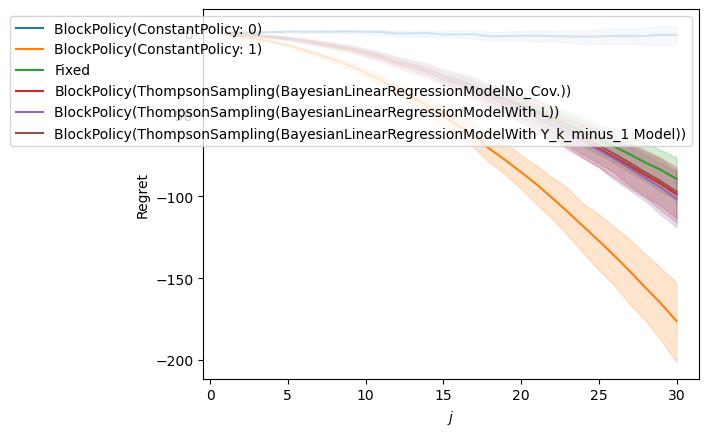

In [43]:
def rename_df(df):
    df["policy_#_metric_#_model_p"] = df["policy"].apply(lambda x: policy_mapping[x] if x in policy_mapping else x)
    # df["policy_#_metric_#_model_p"] = pd.Categorical(
    #     df["policy_#_metric_#_model_p"], categories=policy_ordering[0:5], ordered=True
    # )
    return df


ax = SeriesOfSimulationsData.plot_lines(
    [
        s["result"]
        for s in calculated_series
        #if s["configuration"]["model"] == "SCM_Model_I"
    ],
    [
        CumulativeRegret(),
    ],
    legend_position=(0.8, 1.0),
    process_df=rename_df,
)
plt.ylabel("Regret")
seaborn.move_legend(ax, "upper right", title=None)
#plt.savefig("mt_resources/5-optimization/02_cumulative_regret.pdf", bbox_inches="tight")

:Layout
   .HeatMap.I   :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.I   :Overlay
      .Rectangles.I :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I       :Text   [x,y]
   .HeatMap.II  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.II  :Overlay
      .Rectangles.I :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I       :Text   [x,y]
   .HeatMap.III :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.III :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.IV  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.IV  :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.V   :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.V   :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.VI  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.VI  :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]

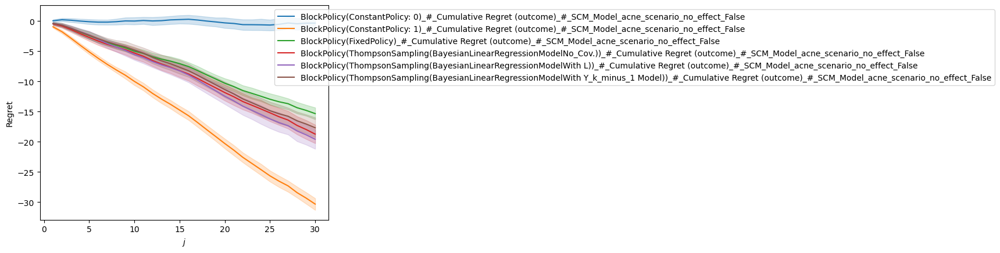

In [44]:
# Experiment 1: Thompson Sampling with and without covariates for acne with only treatment effect
series = [s for s in calculated_series if s["configuration"]["model"] == "SCM_Model_acne_scenario_no_effect"]

ax = SeriesOfSimulationsData.plot_lines(
    [s["result"] for s in series],
    [
        CumulativeRegret(),
    ],
    legend_position=(0.8, 1.0),
)
plot_allocations_for_calculated_series(series)

:Layout
   .HeatMap.I   :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.I   :Overlay
      .Rectangles.I :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I       :Text   [x,y]
   .HeatMap.II  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.II  :Overlay
      .Rectangles.I :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I       :Text   [x,y]
   .HeatMap.III :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.III :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.IV  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.IV  :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.V   :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.V   :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.VI  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.VI  :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]

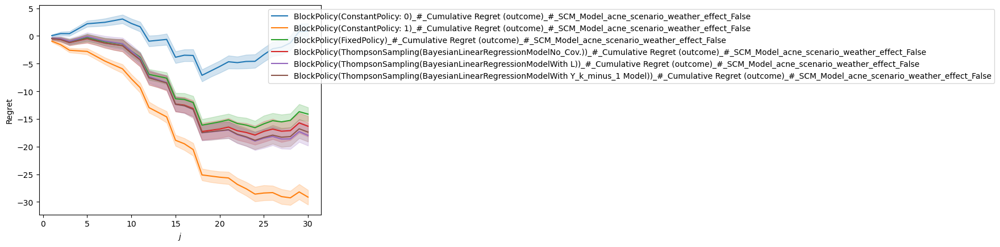

In [45]:
# Experiment 2 Thompson Sampling with and without covariates for acne with weather effect
series = [s for s in calculated_series if s["configuration"]["model"] == "SCM_Model_acne_scenario_weather_effect"]

ax = SeriesOfSimulationsData.plot_lines(
    [s["result"] for s in series],
    [
        CumulativeRegret(),
    ],
    legend_position=(0.8, 1.0),
)
plot_allocations_for_calculated_series(series)

:Layout
   .HeatMap.I   :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.I   :Overlay
      .Rectangles.I :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I       :Text   [x,y]
   .HeatMap.II  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.II  :Overlay
      .Rectangles.I :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I       :Text   [x,y]
   .HeatMap.III :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.III :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.IV  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.IV  :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.V   :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.V   :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]
   .HeatMap.VI  :HeatMap   [j,i]   (color_index,debug_info,context,outcome,counterfactual_outcomes,debug_data,treatment)
   .Overlay.VI  :Overlay
      .Rectangles.I  :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.I        :Text   [x,y]
      .Rectangles.II :Rectangles   [x0,y0,x1,y1]   (value)
      .Text.II       :Text   [x,y]

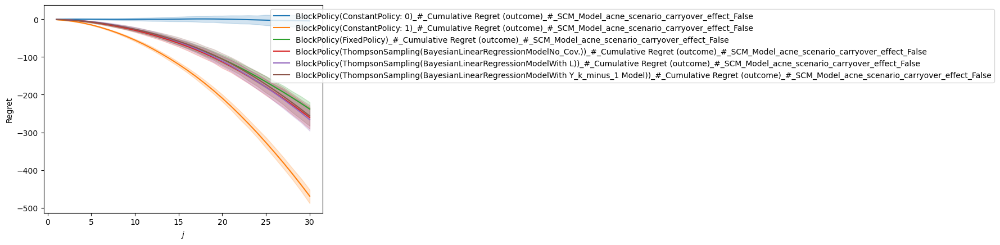

In [46]:
# Experiment 3: Thompson Sampling with and without covariates for acne with carryover effect
series = [s for s in calculated_series if s["configuration"]["model"] == "SCM_Model_acne_scenario_carryover_effect"]

ax = SeriesOfSimulationsData.plot_lines(
    [s["result"] for s in series],
    [
        CumulativeRegret(),
    ],
    legend_position=(0.8, 1.0),
)
plot_allocations_for_calculated_series(series)

In [62]:
filtered_df

,t,score,simulation,patient_id,model,policy,pooled,metric
29,29,-8.128139,SimulationData,0,SCM_Model_acne_scenario_no_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,3.907961,SimulationData,1,SCM_Model_acne_scenario_no_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,0.037019,SimulationData,2,SCM_Model_acne_scenario_no_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,1.170830,SimulationData,3,SCM_Model_acne_scenario_no_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,-2.253248,SimulationData,4,SCM_Model_acne_scenario_no_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
...,...,...,...,...,...,...,...,...
29,29,-152.222475,SimulationData,5,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ThompsonSampling(BayesianLinearReg...,False,Cumulative Regret (outcome)
29,29,-474.057775,SimulationData,6,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ThompsonSampling(BayesianLinearReg...,False,Cumulative Regret (outcome)
29,29,73.201989,SimulationData,7,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ThompsonSampling(BayesianLinearReg...,False,Cumulative Regret (outcome)
29,29,-279.379685,SimulationData,8,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ThompsonSampling(BayesianLinearReg...,False,Cumulative Regret (outcome)


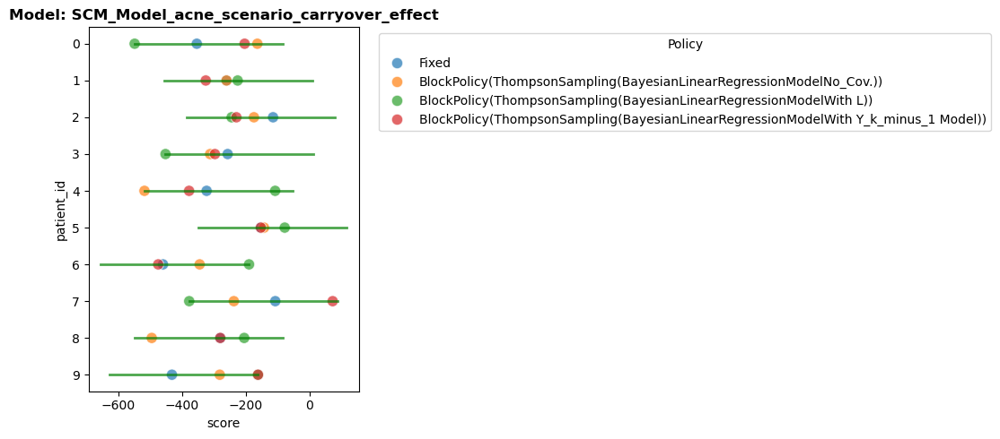

In [97]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

#filtered_df = sklearn_df[sklearn_df["t"] == sklearn_df["t"].max()]
filtered_df = df.loc[df["t"] == df["t"].max()]
filtered_df = filtered_df[filtered_df["patient_id"].astype(int) < 10]

models = filtered_df["model"].unique()
n_cols = 2
n_rows = (len(models) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5 * n_rows))
axes = axes.flatten()

for idx, model in enumerate(models):
    df = filtered_df[filtered_df["model"] == model]
    
    # Scatterplot for other policies
    other_policies = df[~df["policy"].isin([
        "BlockPolicy(ConstantPolicy: 0)",
        "BlockPolicy(ConstantPolicy: 1)"
    ])]
    sns.scatterplot(data=other_policies, x="score", y="patient_id", 
                    hue="policy", ax=axes[idx], s=80, alpha=0.7)
    
    # Add lines for min/max block policies
    block_df = df[df["policy"].isin([
        "BlockPolicy(ConstantPolicy: 0)",
        "BlockPolicy(ConstantPolicy: 1)"
    ])]
    
    for patient_id in block_df["patient_id"].unique():
        patient_data = block_df[block_df["patient_id"] == patient_id]
        
        if len(patient_data) == 2:  # Both min and max exist
            min_score = patient_data[patient_data["policy"] == "BlockPolicy(ConstantPolicy: 0)"]["score"].values[0]
            max_score = patient_data[patient_data["policy"] == "BlockPolicy(ConstantPolicy: 1)"]["score"].values[0]
            
            # Determine color based on effect
            effect = min_score - max_score
            if effect > 1:
                color = 'green'  # Responder (positive effect)
            elif effect >= -1:
                color = 'grey'   # Neutral effect
            else:
                color = 'red'    # Negative effect
            
            # Draw line from min to max
            axes[idx].plot([min_score, max_score], [patient_id, patient_id], 
                          color=color, linewidth=2, alpha=0.7)
    
    axes[idx].set_title(f"Model: {model}", fontsize=12, fontweight='bold')
    axes[idx].legend(title="Policy", bbox_to_anchor=(1.05, 1), loc='upper left')

# Hide unused subplots
for idx in range(len(models), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

In [66]:
df

,t,score,simulation,patient_id,model,policy,pooled,metric
29,29,-83.000570,SimulationData,0,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,10.171090,SimulationData,1,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,81.218734,SimulationData,2,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,13.802910,SimulationData,3,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,-52.214485,SimulationData,4,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,117.777525,SimulationData,5,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,-189.057775,SimulationData,6,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,88.201989,SimulationData,7,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,-84.379685,SimulationData,8,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)
29,29,-160.999430,SimulationData,9,SCM_Model_acne_scenario_carryover_effect,BlockPolicy(ConstantPolicy: 0),False,Cumulative Regret (outcome)


Treatment Effects (ConstantPolicy: 1 - ConstantPolicy: 0):
  patient_id  treatment_effect
0          0            -465.0
1          1            -465.0
2          2            -465.0
3          3            -465.0
4          4            -465.0
5          5            -465.0
6          6            -465.0
7          7            -465.0
8          8            -465.0
9          9            -465.0

Mean treatment effect: -465.00
Std treatment effect: 0.00
Estimated Treatment Effects by Policy:
treatment  patient_id                                             policy  \
0                   0                     BlockPolicy(ConstantPolicy: 0)   
1                   0                     BlockPolicy(ConstantPolicy: 1)   
2                   0                           BlockPolicy(FixedPolicy)   
3                   0  BlockPolicy(ThompsonSampling(BayesianLinearReg...   
4                   0  BlockPolicy(ThompsonSampling(BayesianLinearReg...   
..                ...                         

,mean,std
policy,,
BlockPolicy(ConstantPolicy: 0),NaN,NaN
BlockPolicy(ConstantPolicy: 1),NaN,NaN
BlockPolicy(FixedPolicy),0.365923,2.706229
BlockPolicy(ThompsonSampling(BayesianLinearRegressionModelNo_Cov.)),1.974073,7.296105
BlockPolicy(ThompsonSampling(BayesianLinearRegressionModelWith L)),4.658836,7.116773
BlockPolicy(ThompsonSampling(BayesianLinearRegressionModelWith Y_k_minus_1 Model)),2.727152,6.514404


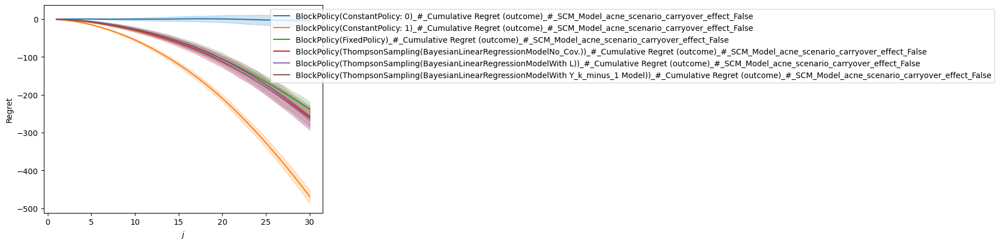

In [89]:
series = [s for s in calculated_series if s["configuration"]["model"] == "SCM_Model_acne_scenario_carryover_effect"]
series

ax = SeriesOfSimulationsData.plot_lines(
    [s["result"] for s in series],
    [
        CumulativeRegret(),
    ],
    legend_position=(0.8, 1.0),
)
plot_allocations_for_calculated_series(series)

# Calculate true treatment effect
series_filtered_df = filtered_df[filtered_df["model"] == "SCM_Model_acne_scenario_carryover_effect"]
series_filtered_df = series_filtered_df[series_filtered_df["t"] == series_filtered_df["t"].max()]

constant_0 = series_filtered_df[series_filtered_df["policy"] == "BlockPolicy(ConstantPolicy: 0)"].set_index("patient_id")["score"]
constant_1 = series_filtered_df[series_filtered_df["policy"] == "BlockPolicy(ConstantPolicy: 1)"].set_index("patient_id")["score"]

treatment_effect = constant_1 - constant_0
treatment_effect_df = pd.DataFrame({
    "patient_id": treatment_effect.index,
    "treatment_effect": treatment_effect.values,
})

print("Treatment Effects (ConstantPolicy: 1 - ConstantPolicy: 0):")
print(treatment_effect_df)
print(f"\nMean treatment effect: {treatment_effect.mean():.2f}")
print(f"Std treatment effect: {treatment_effect.std():.2f}")
# Generate a dataframe from series with patient_id, treatment_assignment, t, covariates
rows = []
for s in series:
    result = s["result"]
    policy_name = s["configuration"]["policy"]
    for sim_data in result.simulations:
        patient_id = sim_data.patient_id
        for t, obs in enumerate(sim_data.history.observations):
            row = {
                "patient_id": patient_id,
                "policy": policy_name,
                "t": t,
                "treatment": obs.treatment.get("treatment", None),
                "outcome": obs.outcome.get("outcome", None),
            }
            # Add covariates from context
            if obs.context:
                for key, value in obs.context.items():
                    row[key] = value
            rows.append(row)

series_df = pd.DataFrame(rows)
series_df

# Estimate treatment effect under each policy by comparing outcomes when treatment=1 vs treatment=0
treatment_effect_by_policy = series_df.groupby(['patient_id', 'policy', 'treatment'])['outcome'].mean().unstack('treatment')
treatment_effect_by_policy['estimated_treatment_effect'] = treatment_effect_by_policy[1] - treatment_effect_by_policy[0]
treatment_effect_by_policy = treatment_effect_by_policy.reset_index()

print("Estimated Treatment Effects by Policy:")
print(treatment_effect_by_policy[['patient_id', 'policy', 'estimated_treatment_effect']])

# Summary statistics by policy
treatment_effect_summary = treatment_effect_by_policy.groupby('policy')['estimated_treatment_effect'].agg(['mean', 'std'])
print("\nTreatment Effect Summary by Policy:")
print(f"\nTrue treatment effect (from constant policies): {true_treatment_effect.mean():.4f} (std: {true_treatment_effect.std():.4f})")
treatment_effect_summary


In [93]:
from sklearn.linear_model import LinearRegression

# G-computation for treatment effect estimation using L and Y_k_minus_1 as covariates

def g_computation_treatment_effect(series_df, patient_id):
    """
    Estimate treatment effect using G-computation.
    Fits an outcome model: E[Y | A, L, Y_{k-1}] and computes counterfactual outcomes.
    """
    patient_data = series_df[series_df['patient_id'] == patient_id].copy()
    
    # Prepare features and outcome
    # Use L and Y_k_minus_1 as covariates, treatment as the intervention
    features = patient_data[['treatment', 'L', 'Y_k_minus_1']].values
    outcomes = patient_data['outcome'].values
    
    # Fit outcome model
    model = LinearRegression()
    model.fit(features, outcomes)
    
    # Compute counterfactual outcomes for each time point
    # Counterfactual under treatment = 1
    features_treat_1 = features.copy()
    features_treat_1[:, 0] = 1
    y_cf_1 = model.predict(features_treat_1)
    
    # Counterfactual under treatment = 0
    features_treat_0 = features.copy()
    features_treat_0[:, 0] = 0
    y_cf_0 = model.predict(features_treat_0)
    
    # Average treatment effect for this patient
    ate = numpy.mean(y_cf_1 - y_cf_0)
    
    return {
        'patient_id': patient_id,
        'ate': ate,
        'y_cf_1': y_cf_1,
        'y_cf_0': y_cf_0,
        'coefficients': model.coef_,
        'intercept': model.intercept_
    }

# Apply G-computation to each patient in series_df (from carryover effect scenario)
g_comp_results = []
for pid in series_df['patient_id'].unique():
    # Filter to policies that have both treatments (exclude constant policies)
    patient_data = series_df[
        (series_df['patient_id'] == pid) & 
        (~series_df['policy'].str.contains('ConstantPolicy'))
    ]
    if len(patient_data) > 0 and patient_data['treatment'].nunique() == 2:
        result = g_computation_treatment_effect(patient_data, pid)
        g_comp_results.append(result)

g_comp_df = pd.DataFrame(g_comp_results)
print("G-Computation Treatment Effect Estimates:")
print(g_comp_df[['patient_id', 'ate']].head(20))
print(f"\nMean ATE across patients: {g_comp_df['ate'].mean():.4f}")
print(f"Std ATE across patients: {g_comp_df['ate'].std():.4f}")
print(f"\nTrue treatment effect: {true_treatment_effect.mean():.4f}")

G-Computation Treatment Effect Estimates:
    patient_id       ate
0            0  1.100211
1            1  1.003875
2            2  0.903609
3            3  1.133071
4            4  0.803211
5            5  1.119075
6            6  1.122736
7            7  0.945657
8            8  1.045571
9            9  1.012509
10          10  1.334410
11          11  1.338579
12          12  0.823197
13          13  0.830278
14          14  0.745687
15          15  1.240050
16          16  1.005923
17          17  1.201425
18          18  0.921053
19          19  0.857316

Mean ATE across patients: 1.0542
Std ATE across patients: 0.1759

True treatment effect: 15.5000


In [96]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression

def gcomp_regime_effect(series_df, patient_id, time_col="t"):
    d = series_df[series_df["patient_id"] == patient_id].copy()
    d = d.sort_values(time_col)

    X = d[["treatment", "L", "Y_k_minus_1"]].values
    y = d["outcome"].values

    model = LinearRegression().fit(X, y)

    # baseline Y0 for simulation
    # Use the first row's Y_k_minus_1 as the "initial" previous outcome
    y_prev_0 = float(d["Y_k_minus_1"].iloc[0])

    L_seq = d["L"].to_numpy()

    def simulate(regime_value):
        y_prev = y_prev_0
        y_path = np.zeros(len(d))
        for k in range(len(d)):
            xk = np.array([[regime_value, L_seq[k], y_prev]])
            yk = float(model.predict(xk))
            y_path[k] = yk
            y_prev = yk
        return y_path

    y_all1 = simulate(1)
    y_all0 = simulate(0)

    return {
        "patient_id": patient_id,
        "ate_path_mean": float(np.mean(y_all1 - y_all0)),   # average over timepoints
        "ate_final": float(y_all1[-1] - y_all0[-1]),        # regime effect at final time
        "y_cf_all1": y_all1,
        "y_cf_all0": y_all0,
        "coef": model.coef_,
        "intercept": float(model.intercept_),
    }

# Apply G-computation per policy
gcomp_results = []
for policy in series_df['policy'].unique():
    policy_df = series_df[series_df['policy'] == policy]
    for pid in policy_df['patient_id'].unique():
        result = gcomp_regime_effect(policy_df, pid)
        result['policy'] = policy
        gcomp_results.append(result)

gcomp_df = pd.DataFrame(gcomp_results)
print("G-Computation Treatment Effect Estimates by Policy:")
print(gcomp_df[['patient_id', 'policy', 'ate_path_mean', 'ate_final']].head(20))

# Summary by policy
gcomp_summary = gcomp_df.groupby('policy')[['ate_path_mean', 'ate_final']].agg(['mean', 'std'])
print("\nG-Computation Summary by Policy:")
gcomp_summary


/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81699/1285608311.py:25: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  yk = float(model.predict(xk))
/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81699/1285608311.py:25: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  yk = float(model.predict(xk))
/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81699/1285608311.py:25: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  yk = float(model.predi

G-Computation Treatment Effect Estimates by Policy:
    patient_id                          policy  ate_path_mean  ate_final
0            0  BlockPolicy(ConstantPolicy: 0)            0.0        0.0
1            1  BlockPolicy(ConstantPolicy: 0)            0.0        0.0
2            2  BlockPolicy(ConstantPolicy: 0)            0.0        0.0
3            3  BlockPolicy(ConstantPolicy: 0)            0.0        0.0
4            4  BlockPolicy(ConstantPolicy: 0)            0.0        0.0
5            5  BlockPolicy(ConstantPolicy: 0)            0.0        0.0
6            6  BlockPolicy(ConstantPolicy: 0)            0.0        0.0
7            7  BlockPolicy(ConstantPolicy: 0)            0.0        0.0
8            8  BlockPolicy(ConstantPolicy: 0)            0.0        0.0
9            9  BlockPolicy(ConstantPolicy: 0)            0.0        0.0
10          10  BlockPolicy(ConstantPolicy: 0)            0.0        0.0
11          11  BlockPolicy(ConstantPolicy: 0)            0.0        0.0

/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81699/1285608311.py:25: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  yk = float(model.predict(xk))
/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81699/1285608311.py:25: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  yk = float(model.predict(xk))
/var/folders/mx/8nbm269n3hv_3jv51d0k5jr40000gp/T/ipykernel_81699/1285608311.py:25: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  yk = float(model.predi

ate_path_mean             \
                                                            mean        std   
policy                                                                        
BlockPolicy(ConstantPolicy: 0)                          0.000000   0.000000   
BlockPolicy(ConstantPolicy: 1)                          0.000000   0.000000   
BlockPolicy(FixedPolicy)                               13.465994   7.801803   
BlockPolicy(ThompsonSampling(BayesianLinearRegr...     11.044929  12.389401   
BlockPolicy(ThompsonSampling(BayesianLinearRegr...     11.522634   8.863809   
BlockPolicy(ThompsonSampling(BayesianLinearRegr...     12.990243   8.439522   

                                                    ate_final             
                                                         mean        std  
policy                                                                    
BlockPolicy(ConstantPolicy: 0)                       0.000000   0.000000  
BlockPolicy(ConstantPolicy: 1)                       0.000000   0.000000  
BlockPolicy(FixedPolicy)                            25.847682  19.311910  
BlockPolicy(ThompsonSampling(BayesianLinearRegr...  22.055489  35.964672  
BlockPolicy(ThompsonSampling(BayesianLinearRegr...  21.476473  18.549664  
BlockPolicy(ThompsonSampling(BayesianLinearRegr...  23.902899  17.934930